# Weekly illegal-dumping demand forecasting

Srinidhi Jaya Revanth Srirangarajapally · Weekly forecasting development experiment. AI assistance supported implementation. The separate final evaluation is documented in FINAL_HANDOFF.md.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / "src/demand_forecasting.py").exists():
    if root == root.parent:
        raise RuntimeError("Open this notebook within the repository")
    root = root.parent
sys.path.insert(0, str(root / "src"))
import pandas as pd
from demand_forecasting import run

## Protocol
Predict each complete Monday–Sunday district-week at its start using only completed prior weeks. Compare fixed Poisson models trained on 2018–2023 and 2020–2023 against identical previous-week and four-week-average baselines. Scaling is fitted on training only. Validation is 2024, ending with the week starting December 23. No final-test metrics are calculated.

In [2]:
scores = run()
scores

            model  training_start  train_rows  validation_rows       mae      rmse
    previous_week            2018        3000              520 15.803846 22.271403
four_week_average            2018        3000              520 15.030288 20.713722
          poisson            2018        3000              520 13.842591 19.414799
    previous_week            2020        2080              520 15.803846 22.271403
four_week_average            2020        2080              520 15.030288 20.713722
          poisson            2020        2080              520 13.642699 19.131701


,model,training_start,train_rows,validation_rows,mae,rmse
0,previous_week,2018,3000,520,15.803846,22.271403
1,four_week_average,2018,3000,520,15.030288,20.713722
2,poisson,2018,3000,520,13.842591,19.414799
3,previous_week,2020,2080,520,15.803846,22.271403
4,four_week_average,2020,2080,520,15.030288,20.713722
5,poisson,2020,2080,520,13.642699,19.131701


## Comparison
Positive improvement below means lower MAE than the four-week baseline. These are validation comparisons, not a claim of statistical significance or final-test performance.

In [3]:
baseline = scores.loc[scores.model.eq("four_week_average"), "mae"].iloc[0]
comparison = scores.loc[scores.model.eq("poisson")].copy()
comparison["mae_improvement_percent"] = 100 * (baseline - comparison.mae) / baseline
comparison

,model,training_start,train_rows,validation_rows,mae,rmse,mae_improvement_percent
2,poisson,2018,3000,520,13.842591,19.414799,7.902026
5,poisson,2020,2080,520,13.642699,19.131701,9.231952


In [4]:
pd.read_csv(root / "results/demand_forecasting/location_audit.csv")

,year,location_matches,requests
0,2018,0,44
1,2018,1,22665
2,2019,0,64
3,2019,1,24425
4,2020,0,49
5,2020,1,26790
6,2021,0,85
7,2021,1,27455
8,2022,0,95
9,2022,1,22616


In [5]:
pd.read_csv(root / "results/demand_forecasting/district_metrics.csv")

,experiment,district,mae,rmse
0,previous_week_2018,1,22.519231,27.640898
1,previous_week_2018,2,18.346154,23.409400
2,previous_week_2018,3,29.423077,38.839413
3,previous_week_2018,4,9.288462,11.241236
4,previous_week_2018,5,23.307692,29.805136
5,previous_week_2018,6,11.769231,15.525413
6,previous_week_2018,7,16.115385,21.603062
7,previous_week_2018,8,12.096154,15.271265
8,previous_week_2018,9,5.980769,7.818863
9,previous_week_2018,10,9.192308,11.083598


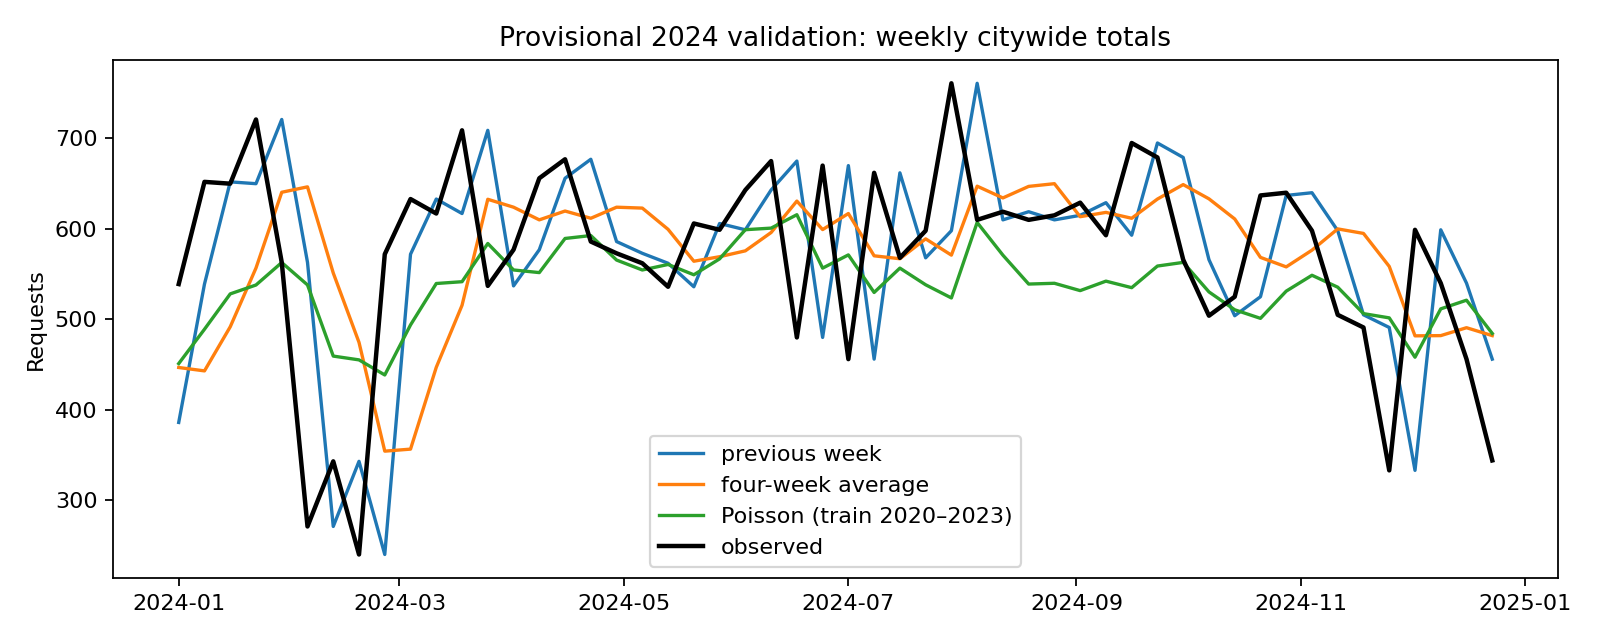

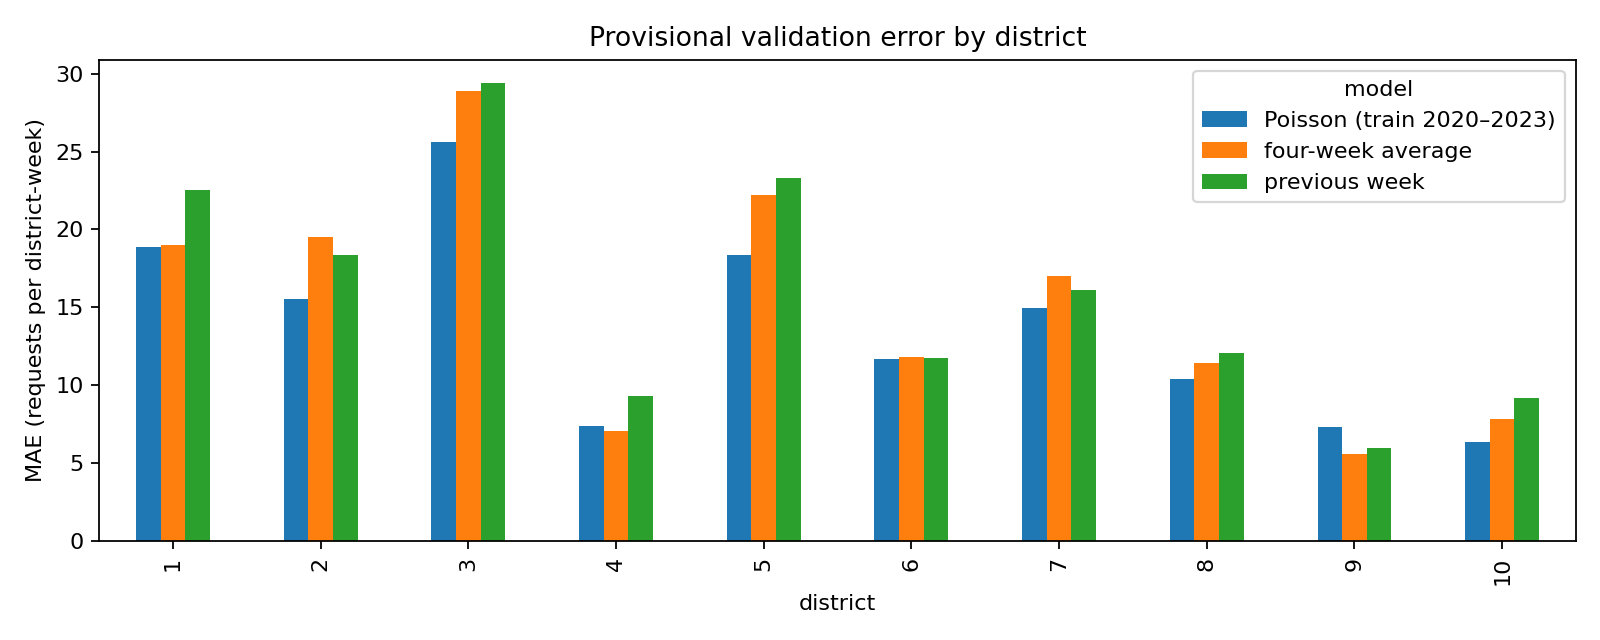

In [6]:
from IPython.display import Image, display
display(Image(filename=str(root / "reports/figures/demand_forecasting/validation_timeseries.png")))
display(Image(filename=str(root / "reports/figures/demand_forecasting/district_mae.png")))

## Interpretation and remaining dependencies
Choose the training window using validation, then agree on the shared team protocol before final testing. A longer history can include older reporting patterns and does not necessarily improve current forecasts. All values depend on the retained request sample and the fixed current district geography. Resolve source timezone and completeness, upstream coordinate exclusions, and team district-map approval before treating these as final results. The README documents sources and limitations. The literature review, personal interpretation, and official AI-use certificate require student completion and verification.